In [68]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/clean/selected_features.csv", sep=",")

display(df.head())
print(f"\nThe shape is: {df.shape}")
print(f"\nThe columns are: {df.columns}")

,application_mode_group,course_name,prev_qual_level,debtor,tuition_fees_up_to_date,gender,scholarship_holder,curricular_units_2nd_sem_enrolled,curricular_units_2nd_sem_approved,curricular_units_2nd_sem_grade,age_at_enrollment,admission_grade,target
0,2nd phase - general contingent,Animation and Multimedia Design,2,0,1,1,0,0,0,0.000000,20,127.3,Dropout
1,International student (bachelor),Tourism,2,0,0,1,0,6,6,13.666667,19,142.5,Graduate
2,1st phase - general contingent,Communication Design,2,0,0,1,0,6,0,0.000000,19,124.8,Dropout
3,2nd phase - general contingent,Journalism and Communication,2,0,1,0,0,6,5,12.400000,20,119.6,Graduate
4,Over 23 years old,Social Service (evening attendance),2,0,1,0,0,6,6,13.000000,45,141.5,Graduate



The shape is: (3630, 13)

The columns are: Index(['application_mode_group', 'course_name', 'prev_qual_level', 'debtor',
       'tuition_fees_up_to_date', 'gender', 'scholarship_holder',
       'curricular_units_2nd_sem_enrolled',
       'curricular_units_2nd_sem_approved', 'curricular_units_2nd_sem_grade',
       'age_at_enrollment', 'admission_grade', 'target'],
      dtype='str')


In [69]:
#Check for enrolled students
df["target"].unique()

<StringArray>
['Dropout', 'Graduate']
Length: 2, dtype: str

In [70]:
#Save enrolled students for risk prediction
df_enrolled = df[df["target"] == "Enrolled"].copy()

#Exclude enrolled students from training
df = df[df["target"] != "Enrolled"].copy()

In [72]:
df_enrolled

,application_mode_group,course_name,prev_qual_level,debtor,tuition_fees_up_to_date,gender,scholarship_holder,curricular_units_2nd_sem_enrolled,curricular_units_2nd_sem_approved,curricular_units_2nd_sem_grade,age_at_enrollment,admission_grade,target


In [7]:
df["target"].unique()

<StringArray>
['Dropout', 'Graduate']
Length: 2, dtype: str

In [8]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.preprocessing import MinMaxScaler, StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, accuracy_score
import matplotlib.pyplot as plt
from sklearn.metrics import (precision_score, recall_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)

RANDOM_STATE = 42

In [10]:
#SPLIT THE DATA FRAME (PLACEHOLDER)
X = df.drop(columns='target')
y = df['target']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2,
    random_state=RANDOM_STATE, stratify=y
)

In [11]:
nominal_features = ['application_mode_group', 'course_name']

ordinal_features = ["prev_qual_level"]

binary_features = ["debtor", "tuition_fees_up_to_date", "gender", "scholarship_holder"]

numerical_features = [
    "admission_grade",
    "age_at_enrollment",
    "curricular_units_2nd_sem_enrolled",
    "curricular_units_2nd_sem_approved",
    "curricular_units_2nd_sem_grade"
]

In [12]:
ordinal_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaling", MinMaxScaler()),
])
nominal_pipeline = Pipeline([("encoding", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
numerical_pipeline = Pipeline([("scaling", MinMaxScaler())])

In [13]:
# Preprocessor for column transformation
preprocessor = ColumnTransformer([
    ("ordinal", ordinal_pipeline, ordinal_features),
    ("nominal", nominal_pipeline, nominal_features),
    ("numerical", numerical_pipeline, numerical_features),
    ("binary", "passthrough", binary_features),
])

In [14]:
# Run KNN Model and fit
knn_pipeline = Pipeline([("preprocess", preprocessor),
                         ("model", KNeighborsClassifier(n_neighbors=5))])
knn_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['Dropout','Graduate']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['application_mode_group','course_name','prev_qual_level',..., 'curricular_units_2nd_sem_grade','age_at_enrollment','admission_grade']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('ordinal', ...), ('nominal', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specified

In [15]:
# Check Training vs Test Accuracy
print("Training accuracy:", round(knn_pipeline.score(X_train, y_train), 3))
print("Test accuracy:", round(knn_pipeline.score(X_test, y_test), 3))

Training accuracy: 0.882
Test accuracy: 0.825


In [16]:
y_pred_train_knn = knn_pipeline.predict(X_train)
y_pred_test_knn  = knn_pipeline.predict(X_test)

comparison_students = pd.DataFrame({
    "actual_student_status": y_test,
    "predicted_student_status": pd.Series(y_pred_test_knn, index=y_test.index),
})

display(comparison_students.head(10))

,actual_student_status,predicted_student_status
3060,Dropout,Dropout
13,Graduate,Graduate
1808,Graduate,Graduate
3228,Graduate,Graduate
1694,Graduate,Graduate
1664,Dropout,Dropout
595,Graduate,Dropout
1199,Graduate,Graduate
2772,Graduate,Graduate
2098,Graduate,Graduate


In [17]:
classification_metrics = pd.DataFrame({
    "Training": {
        "Accuracy": accuracy_score(y_train, y_pred_train_knn),
        "Precision (macro)": precision_score(y_train, y_pred_train_knn, average='macro'),
        "Recall (macro)": recall_score(y_train, y_pred_train_knn, average='macro'),
        "Recall (Dropout)": recall_score(y_train, y_pred_train_knn, pos_label="Dropout"),
    },
    "Test": {
        "Accuracy": accuracy_score(y_test, y_pred_test_knn),
        "Precision (macro)": precision_score(y_test, y_pred_test_knn, average='macro'),
        "Recall (macro)": recall_score(y_test, y_pred_test_knn, average='macro'),
        "Recall (Dropout)": recall_score(y_test, y_pred_test_knn, pos_label="Dropout"),
    },
})
display(classification_metrics.round(3))

,Training,Test
Accuracy,0.882,0.825
Precision (macro),0.890,0.830
Recall (macro),0.862,0.799
Recall (Dropout),0.770,0.680


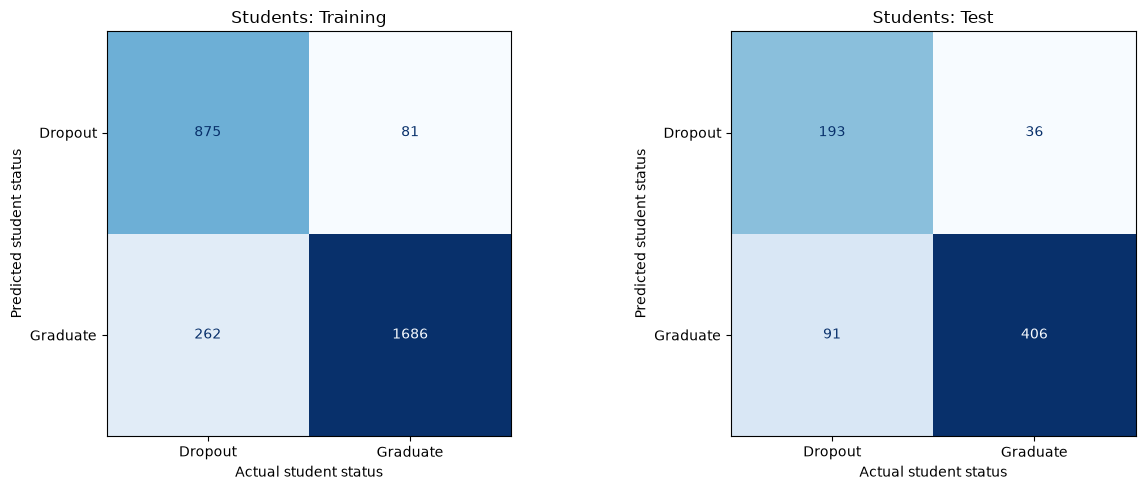

In [18]:
# One class order, used by both the matrix and the labels
class_order = ["Dropout", "Graduate"]

# Compute confusion matrices for both datasets
cm_train = confusion_matrix(y_train, y_pred_train_knn, labels=class_order)
cm_test  = confusion_matrix(y_test,  y_pred_test_knn,  labels=class_order)

# Plot the confusion matrices: train vs test
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, cm, split_name in zip(axes, [cm_train, cm_test], ["Training", "Test"]):
    # Transpose: predicted classes on rows, actual classes on columns.
    ConfusionMatrixDisplay(
        confusion_matrix=cm.T,
        display_labels=class_order,
    ).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_xlabel("Actual student status")
    ax.set_ylabel("Predicted student status")
    ax.set_title(f"Students: {split_name}")

plt.tight_layout()
plt.show()

## RANDOM FOREST CLASSIFIER MODEL

**Notes**
- We will use the same preprocesser and apply the RandomForestClassifier
- The code will be similar to the 7.3 notebooks and previous evaluations metrics from notebooks 7.1 - 7.2
  

In [61]:
#import random forest classifier
from sklearn.ensemble import RandomForestClassifier

N_ESTIMATORS = 60  # Same fixed value as 7.3.2; tuning comes later

In [62]:
#apply pipeline with random forest classifer
forest_pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=N_ESTIMATORS,
        max_depth=6,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )),
])
forest_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['Dropout','Graduate']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['application_mode_group','course_name','prev_qual_level',..., 'curricular_units_2nd_sem_grade','age_at_enrollment','admission_grade']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('ordinal', ...), ('nominal', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specified

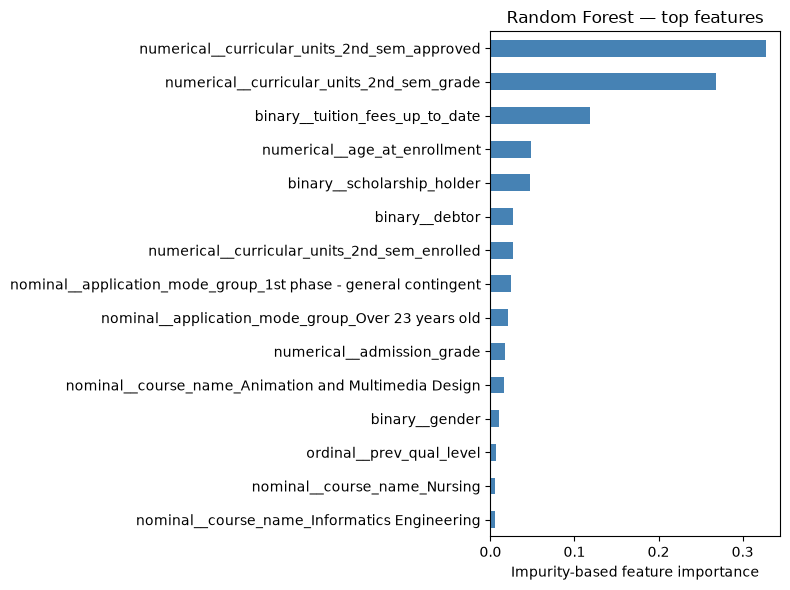

In [63]:
# Display the most important features of the model
forest = forest_pipeline.named_steps["model"]

feature_names = forest_pipeline.named_steps["preprocess"].get_feature_names_out()

forest_importances = pd.Series(
    forest.feature_importances_, index=feature_names
).sort_values().tail(15)

fig, ax = plt.subplots(figsize=(8, 6))
forest_importances.plot.barh(ax=ax, color="steelblue")
ax.set(xlabel="Impurity-based feature importance",
       title="Random Forest — top features")
plt.tight_layout()
plt.show()

In [24]:
# Check Training vs Test Accuracy
print("Training accuracy:", round(forest_pipeline.score(X_train, y_train), 3))
print("Test accuracy:", round(forest_pipeline.score(X_test, y_test), 3))

Training accuracy: 0.913
Test accuracy: 0.908


In [33]:
# Should a comparison table
y_pred_train_rf = forest_pipeline.predict(X_train)
y_pred_test_rf  = forest_pipeline.predict(X_test)

comparison_students_rf = pd.DataFrame({
    "actual_student_status": y_test,
    "predicted_student_status": pd.Series(y_pred_test_rf, index=y_test.index),
})

display(comparison_students_rf.head(10))

,actual_student_status,predicted_student_status
3060,Dropout,Graduate
13,Graduate,Graduate
1808,Graduate,Graduate
3228,Graduate,Graduate
1694,Graduate,Graduate
1664,Dropout,Dropout
595,Graduate,Graduate
1199,Graduate,Graduate
2772,Graduate,Graduate
2098,Graduate,Graduate


In [27]:
# List classification metrics for evaluation of model
classification_metrics_rf = pd.DataFrame({
    "Training": {
        "Accuracy": accuracy_score(y_train, y_pred_train_rf),
        "Precision (macro)": precision_score(y_train, y_pred_train_rf, average='macro'),
        "Recall (macro)": recall_score(y_train, y_pred_train_rf, average='macro'),
        "Recall (Dropout)": recall_score(y_train, y_pred_train_rf, pos_label="Dropout"),
    },
    "Test": {
        "Accuracy": accuracy_score(y_test, y_pred_test_rf),
        "Precision (macro)": precision_score(y_test, y_pred_test_rf, average='macro'),
        "Recall (macro)": recall_score(y_test, y_pred_test_rf, average='macro'),
        "Recall (Dropout)": recall_score(y_test, y_pred_test_rf, pos_label="Dropout"),
    },
})
display(classification_metrics_rf.round(3))

,Training,Test
Accuracy,0.913,0.908
Precision (macro),0.924,0.917
Recall (macro),0.895,0.890
Recall (Dropout),0.814,0.810


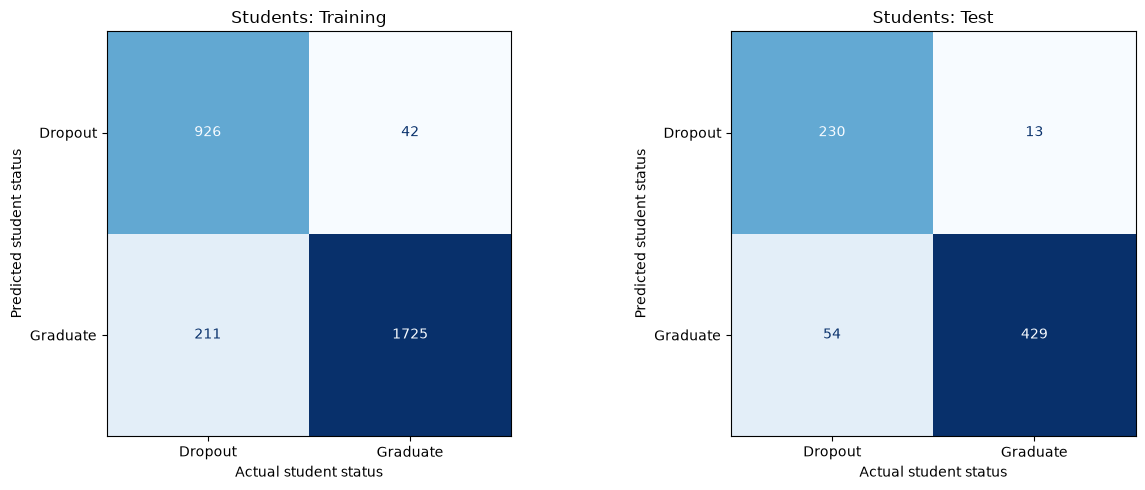

In [28]:
# Compute confusion matrices for both datasets
cm_train_rf = confusion_matrix(y_train, y_pred_train_rf, labels=class_order)
cm_test_rf  = confusion_matrix(y_test,  y_pred_test_rf,  labels=class_order)

# Plot the confusion matrices: train vs test
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, cm, split_name in zip(axes, [cm_train_rf, cm_test_rf], ["Training", "Test"]):
    # Transpose: predicted classes on rows, actual classes on columns.
    ConfusionMatrixDisplay(
        confusion_matrix=cm.T,
        display_labels=class_order,
    ).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_xlabel("Actual student status")
    ax.set_ylabel("Predicted student status")
    ax.set_title(f"Students: {split_name}")

plt.tight_layout()
plt.show()

In [51]:
results = []

def evaluate_classifier(name, fitted_pipeline):
    """Record accuracy, Dropout precision and recall"""
    pred_train = fitted_pipeline.predict(X_train)
    pred_test = fitted_pipeline.predict(X_test)
    scores = {
        "Model": name,
        "Train accuracy": accuracy_score(y_train, pred_train),
        "Test accuracy": accuracy_score(y_test, pred_test),
        "Test precision (Dropout)": precision_score(y_test, pred_test, pos_label="Dropout"),
        "Test recall (Dropout)": recall_score(y_test, pred_test, pos_label="Dropout"),
    }
    results.append(scores)
    return pd.Series(scores)

# Record both models you've built so far
evaluate_classifier("KNN", knn_pipeline)
evaluate_classifier("Random Forest", forest_pipeline)

display(pd.DataFrame(results).set_index("Model").round(3))

,Train accuracy,Test accuracy,Test precision (Dropout),Test recall (Dropout)
Model,,,,
KNN,0.882,0.825,0.843,0.68
Random Forest,0.913,0.908,0.947,0.81


## GRID SEARCH CV TO TUNE HYPERPARAMETERS DEPTH AND LEAFS

In [39]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer, f1_score

In [47]:
forest_search_pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("model", RandomForestClassifier(
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ))])

parameter_grid = {
        "model__n_estimators": [30, 40, 50, 60, 70, 80, 90, 100],  # Integers from 30 to 100
        "model__max_depth": [3, 4, 5, 6, 7, 8, 9, 10, 11, 12],      # Integers from 3 to 12
    }

forest_search = GridSearchCV(
        estimator=forest_search_pipeline,
        param_grid=parameter_grid,
        scoring=make_scorer(f1_score, pos_label="Dropout"),
        cv=4,
        refit=True,
        n_jobs=1,  # Avoid nested parallelism (Random Forest uses n_jobs=-1).
    )

forest_search.fit(X_train, y_train)

print("Best hyperparameters:", forest_search.best_params_)
print(f"Best mean CV F1 (Dropout): {forest_search.best_score_:.3f}")

Best hyperparameters: {'model__max_depth': 10, 'model__n_estimators': 100}
Best mean CV F1 (Dropout): 0.866


In [48]:
pd.DataFrame(forest_search.cv_results_)

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_model__max_depth,param_model__n_estimators,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,mean_test_score,std_test_score,rank_test_score
0,0.148034,0.019577,0.052163,0.008470,3,30,"{'model__max_depth': 3, 'model__n_estimators':...",0.797619,0.872659,0.825832,0.851920,0.837007,0.028150,76
1,0.153631,0.003466,0.051540,0.004393,3,40,"{'model__max_depth': 3, 'model__n_estimators':...",0.800789,0.868914,0.825832,0.855046,0.837645,0.026356,75
2,0.254010,0.106451,0.055807,0.002227,3,50,"{'model__max_depth': 3, 'model__n_estimators':...",0.800000,0.872865,0.823529,0.850829,0.836806,0.027513,77
3,0.216990,0.005513,0.056722,0.003507,3,60,"{'model__max_depth': 3, 'model__n_estimators':...",0.800000,0.866920,0.817289,0.848708,0.833229,0.026139,80
4,0.236174,0.005288,0.062250,0.001399,3,70,"{'model__max_depth': 3, 'model__n_estimators':...",0.805501,0.871698,0.824219,0.853480,0.838724,0.025589,73
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
75,0.235277,0.009147,0.063618,0.003984,12,60,"{'model__max_depth': 12, 'model__n_estimators'...",0.823985,0.889720,0.864151,0.873394,0.862812,0.024215,28
76,0.270039,0.006422,0.070217,0.006247,12,70,"{'model__max_depth': 12, 'model__n_estimators'...",0.826255,0.894249,0.863636,0.875458,0.864899,0.024839,9
77,0.301381,0.012259,0.066509,0.005617,12,80,"{'model__max_depth': 12, 'model__n_estimators'...",0.830769,0.890130,0.859848,0.875458,0.864051,0.021998,13
78,0.310599,0.009621,0.067833,0.004353,12,90,"{'model__max_depth': 12, 'model__n_estimators'...",0.828516,0.888060,0.861480,0.876611,0.863667,0.022377,18


In [53]:
cv_results = pd.DataFrame(forest_search.cv_results_)
summary = cv_results[[
    "param_model__max_depth",
    "param_model__n_estimators",
    "mean_test_score",  # sklearn calls the held-out CV fold "test" here.
    "std_test_score",
    "rank_test_score",
]].copy()
summary.sort_values("rank_test_score").head(20)

,param_model__max_depth,param_model__n_estimators,mean_test_score,std_test_score,rank_test_score
63,10,100,0.865872,0.024226,1
67,11,60,0.865715,0.023133,2
61,10,80,0.865470,0.022636,3
66,11,50,0.865390,0.020211,4
53,9,80,0.865072,0.024560,5
52,9,70,0.865044,0.025256,6
58,10,50,0.864991,0.024003,7
60,10,70,0.864950,0.022312,8
76,12,70,0.864899,0.024839,9
68,11,70,0.864590,0.025229,10


In [55]:
final_forest = Pipeline([
    ("preprocess", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )),
])
final_forest.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['Dropout','Graduate']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['application_mode_group','course_name','prev_qual_level',..., 'curricular_units_2nd_sem_grade','age_at_enrollment','admission_grade']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('ordinal', ...), ('nominal', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specified

In [56]:
evaluate_classifier("Random Forest (depth 10, 100 trees)", final_forest)

Model                       Random Forest (depth 10, 100 trees)
Train accuracy                                         0.942837
Test accuracy                                          0.909091
Test precision (Dropout)                               0.946721
Test recall (Dropout)                                   0.81338
dtype: object

In [57]:
display(pd.DataFrame(results).set_index("Model").round(3))

,Train accuracy,Test accuracy,Test precision (Dropout),Test recall (Dropout)
Model,,,,
KNN,0.882,0.825,0.843,0.680
Random Forest,0.913,0.908,0.947,0.810
"Random Forest (depth 10, 100 trees)",0.943,0.909,0.947,0.813


**TAKEAWAYS**
- Grid search added deeper trees without improving test performance.
- Depth 6 is the simpler one, with less overfitting.
- Random Forest does represent and improvement over KNN, particularly for Test Recall

## Apply to df_enrolled

In [75]:
# Import df_enrolled
df_enrolled = pd.read_csv("../data/clean/enrolled_selected_features.csv", sep=",")

display(df.head())
print(f"\nThe shape is: {df.shape}")
print(f"\nThe columns are: {df.columns}")

,application_mode_group,course_name,prev_qual_level,debtor,tuition_fees_up_to_date,gender,scholarship_holder,curricular_units_2nd_sem_enrolled,curricular_units_2nd_sem_approved,curricular_units_2nd_sem_grade,age_at_enrollment,admission_grade
0,3rd phase - general contingent,Social Service,2,0,1,0,0,6,2,11.000,18,137.4
1,1st phase - general contingent,Basic Education,2,0,1,0,0,7,6,13.500,18,124.6
2,3rd phase - general contingent,Oral Hygiene,2,0,1,0,0,8,8,11.425,20,121.8
3,1st phase - general contingent,Social Service,2,1,1,0,1,6,4,11.000,18,157.0
4,1st phase - general contingent,Veterinary Nursing,2,0,1,0,0,5,4,13.000,18,131.0



The shape is: (794, 12)

The columns are: Index(['application_mode_group', 'course_name', 'prev_qual_level', 'debtor',
       'tuition_fees_up_to_date', 'gender', 'scholarship_holder',
       'curricular_units_2nd_sem_enrolled',
       'curricular_units_2nd_sem_approved', 'curricular_units_2nd_sem_grade',
       'age_at_enrollment', 'admission_grade'],
      dtype='str')


In [94]:
# Create the predicition with the final forest model
X_enrolled = df_enrolled.copy()
y_pred_enrolled_rf = final_forest.predict(X_enrolled)

In [95]:
#Create a column of predicted status
df_enrolled["predicted_status"] = y_pred_enrolled_rf

In [96]:
print(df_enrolled["predicted_status"].value_counts())

predicted_status
Graduate    459
Dropout     335
Name: count, dtype: int64
